In [3]:
import plotly.graph_objects as go

def partner(x):                    # the word across the fold: mirror image; a palindrome takes its complement
    r = x[::-1]
    return r if r != x else "".join("1" if c == "0" else "0" for c in x)

def grow(L):                       # ends first (all 0 / all 1), each next pair goes in the exact center; last pair swapped
    seen, pairs = set(), []
    for w in range(1 << L):
        x = format(w, f"0{L}b")
        if x in seen: continue
        p = partner(x); seen |= {x, p}; pairs.append((x, p))
    seq = []
    for i, (a, b) in enumerate(pairs):
        if i == len(pairs) - 1 and len(pairs) > 1: a, b = b, a
        m = len(seq) // 2
        seq = seq[:m] + [a, b] + seq[m:]
    return seq

def ring_figure(n):
    ring = grow(n); bits = "".join(ring); N = len(bits); G = len(ring)
    step, gstep = 360 / N, 360 / G
    fig = go.Figure()
    fig.add_trace(go.Barpolar(                       # one slice per bit
        theta=[(i + 0.5) * step for i in range(N)], r=[n] * N, base=[n] * N, width=[step] * N,
        marker=dict(color=["#1D9E75" if b == "1" else "#E4E4E4" for b in bits], line=dict(width=0)),
        hovertext=[f"{ring[i // n]}  (slice {i % n + 1} = {b})" for i, b in enumerate(bits)], hoverinfo="text", showlegend=False))
    fig.add_trace(go.Barpolar(                       # outline of each word (group)
        theta=[(j + 0.5) * gstep for j in range(G)], r=[n] * G, base=[n] * G, width=[gstep] * G,
        marker=dict(color="rgba(0,0,0,0)", line=dict(color="#333", width=1.5 if G <= 64 else 0.6)),
        hovertext=ring, hoverinfo="text", showlegend=False))
    if N <= 64:                                      # print the bits on the slices when they fit
        fig.add_trace(go.Scatterpolar(theta=[(i + 0.5) * step for i in range(N)], r=[1.5 * n] * N, mode="text",
                                      text=list(bits), textfont=dict(size=12), hoverinfo="skip", showlegend=False))
    fig.update_layout(title=f"Ring of bit length {n}: {G} words, {N} slices (clockwise from the top)", height=720,
                      polar=dict(bgcolor="rgba(0,0,0,0)", radialaxis=dict(visible=False, range=[0, 2 * n]),
                                 angularaxis=dict(direction="clockwise", rotation=90, showticklabels=False, showgrid=False, showline=False)))
    return ring, fig

Bit length?  4


0000
0001
0010
0011
0101
0110
0111
1101
1011
1110
1001
1010
1100
0100
1000
1111


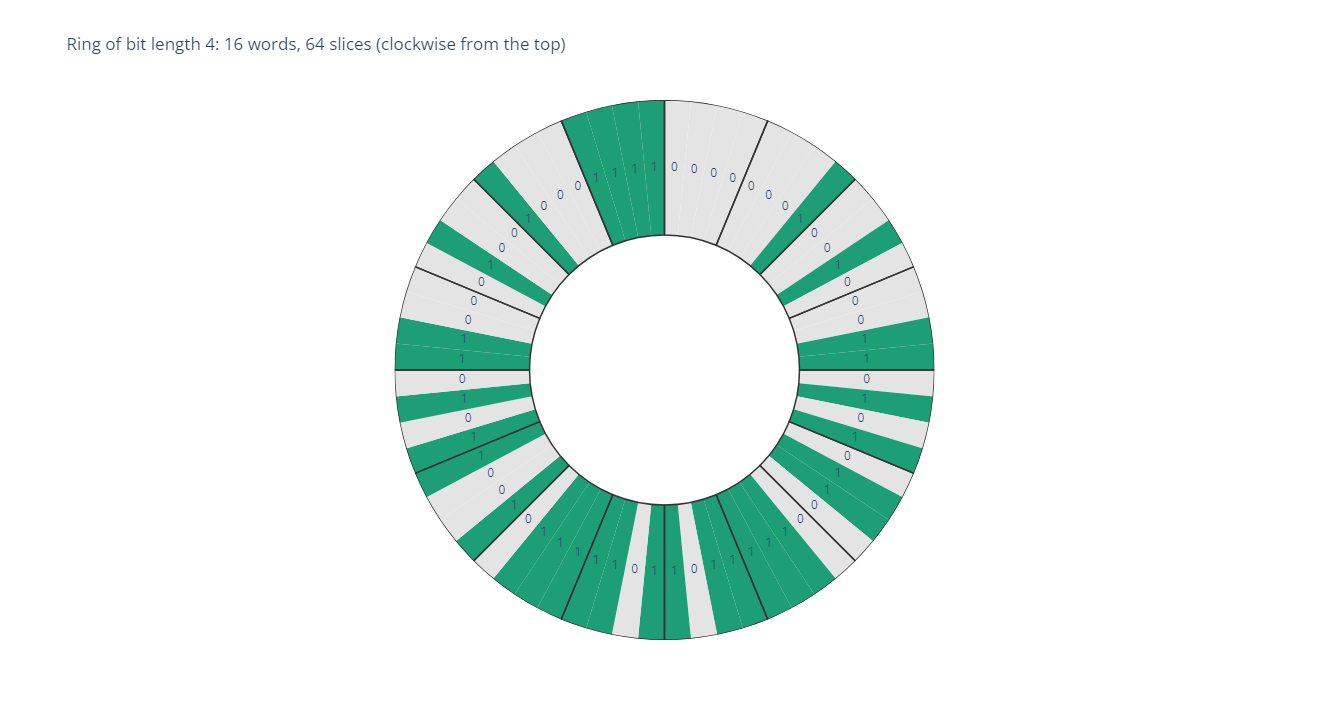

In [5]:
n = int(input("Bit length? "))
if n < 1 or n > 12:
    print("Pick 1 to 12 (12 already means 4096 words).")
else:
    ring, fig = ring_figure(n)
    print("\n".join(ring))
    fig.show()